# Домашняя работа №1. Анализ временного ряда продаж

**Датасет:** [Online Retail (UCI)](https://archive.ics.uci.edu/dataset/352/online+retail)  
**Товар:** `22423`  REGENCY CAKESTAND 3 TIER  
**Показатель:** количество проданных единиц (`Quantity`) без отменённых заказов и возвратов.

Цель работы : построить временной ряд, проверить качество данных, исследовать сезонность и стационарность. Прогнозирование в этой работе не выполняется.

### Библиотеки

Загружаем библиотеки для работы с данными и временными рядами.

In [20]:
from pathlib import Path
import io
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import median_abs_deviation
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True

stock_code = '22423'

## Шаг 1. Подготовка временного ряда

### 1.1. Загрузка данных

Считываем Online Retail и проверяем даты, типы данных и пропуски. Для анализа понадобятся `StockCode`, `InvoiceDate`, `InvoiceNo`, `Quantity` и `UnitPrice`.

In [21]:
def load_retail():
    folders = [Path('/kaggle/input'), Path('data')]
    excel_files = []
    zip_files = []

    for folder in folders:
        if folder.exists():
            excel_files += list(folder.rglob('Online Retail.xlsx'))
            zip_files += list(folder.rglob('online+retail.zip'))

    if excel_files:
        df = pd.read_excel(excel_files[0], dtype={'InvoiceNo': str, 'StockCode': str})
    elif zip_files:
        with zipfile.ZipFile(zip_files[0]) as archive:
            file = io.BytesIO(archive.read('Online Retail.xlsx'))
            df = pd.read_excel(file, dtype={'InvoiceNo': str, 'StockCode': str})
    else:
        raise FileNotFoundError('Добавьте Online Retail.xlsx или online+retail.zip в Kaggle Input')

    df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')
    df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
    df['UnitPrice'] = pd.to_numeric(df['UnitPrice'], errors='coerce')
    df['StockCode'] = df['StockCode'].astype('string').str.strip()
    return df


raw = load_retail()
print('Размер таблицы:', raw.shape)
print('Период:', raw.InvoiceDate.min(), '—', raw.InvoiceDate.max())
display(raw.head())
display(raw.isna().sum().to_frame('Пропуски'))
display(raw.dtypes.to_frame('Тип данных'))

Размер таблицы: (541909, 8)
Период: 2010-12-01 08:26:00 — 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,Пропуски
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


,Тип данных
InvoiceNo,object
StockCode,string[python]
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object


В датасете 541 909 строк за период с 01.12.2010 по 09.12.2011. Перед агрегацией очистим транзакции.

### 1.2. Очистка данных и выбор товара

Исключаем отмены, неположительные количество и цену, а также строки без даты и кода товара. Анализируем количество положительных продаж товара `22423`, а не продажи за вычетом возвратов.

In [22]:
def clean_sales(df):
    cancelled = df['InvoiceNo'].fillna('').str.startswith('C')
    mask = (
        ~cancelled
        & df['InvoiceDate'].notna()
        & df['StockCode'].notna()
        & (df['Quantity'] > 0)
        & (df['UnitPrice'] > 0)
    )
    return df.loc[mask].copy()


sales = clean_sales(raw)
sales['date'] = sales['InvoiceDate'].dt.normalize()
item = sales[sales['StockCode'] == stock_code].copy()

print('Строк после очистки:', len(sales))
print('Удалено строк:', len(raw) - len(sales))
print('Товар:', item['Description'].mode().iloc[0])
print('Записей:', len(item))
print('Продано единиц:', int(item['Quantity'].sum()))
display(item.head())

Строк после очистки: 530104
Удалено строк: 11805
Товар: REGENCY CAKESTAND 3 TIER
Записей: 2017
Продано единиц: 13879


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,date
880,536477,22423,REGENCY CAKESTAND 3 TIER,16,2010-12-01 12:27:00,10.95,16210.0,United Kingdom,2010-12-01
936,536502,22423,REGENCY CAKESTAND 3 TIER,2,2010-12-01 12:36:00,12.75,16552.0,United Kingdom,2010-12-01
1092,536525,22423,REGENCY CAKESTAND 3 TIER,2,2010-12-01 12:54:00,12.75,14078.0,United Kingdom,2010-12-01
1155,536528,22423,REGENCY CAKESTAND 3 TIER,1,2010-12-01 13:17:00,12.75,15525.0,United Kingdom,2010-12-01
1197,536530,22423,REGENCY CAKESTAND 3 TIER,1,2010-12-01 13:21:00,12.75,17905.0,United Kingdom,2010-12-01


После очистки осталось 530 104 строки. По товару `22423` 2 017 записей и 13 879 проданных единиц.

### 1.3. Агрегация

Строим дневной, недельный и месячный ряды, суммируя `Quantity`. Дни без продаж товара отмечаем нулём, только если в этот день были другие транзакции магазина, при полном отсутствии записей оставляем NaN.

Дней: 374 | недель: 54 | месяцев: 13
Дней без данных: 69 | дней с нулевыми продажами: 4


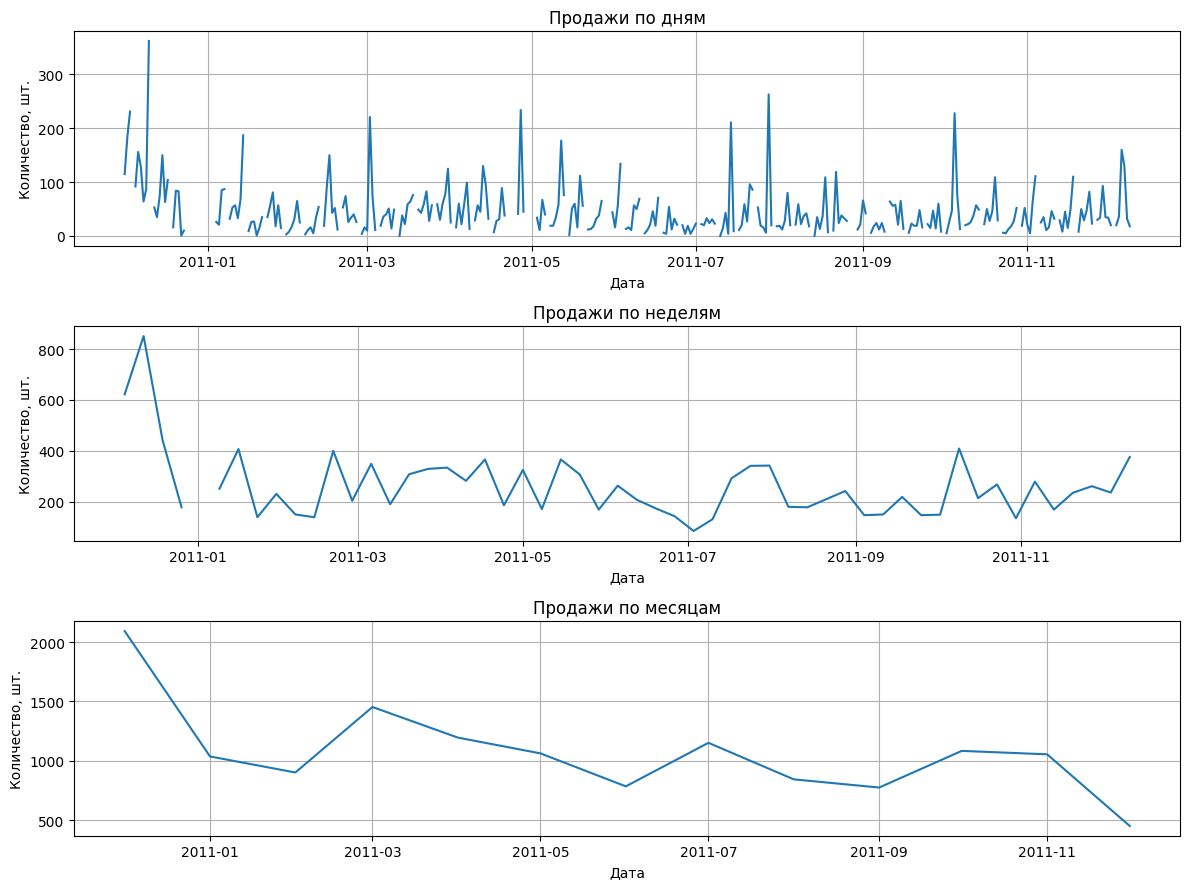

In [23]:
def build_series(item, sales):
    dates = pd.date_range(sales['date'].min(), sales['date'].max(), freq='D')
    shop_days = sales['date'].unique()

    daily = item.groupby('date')['Quantity'].sum().reindex(dates).astype(float)
    daily.loc[daily.isna() & daily.index.isin(shop_days)] = 0

    weekly = daily.resample('W-SUN').sum(min_count=1)
    monthly = daily.resample('MS').sum(min_count=1)
    return daily, weekly, monthly


daily, weekly, monthly = build_series(item, sales)
print('Дней:', len(daily), '| недель:', len(weekly), '| месяцев:', len(monthly))
print('Дней без данных:', daily.isna().sum(), '| дней с нулевыми продажами:', daily.eq(0).sum())

fig, axes = plt.subplots(3, 1, figsize=(12, 9))
for ax, s, title in zip(axes, [daily, weekly, monthly],
                        ['Продажи по дням', 'Продажи по неделям', 'Продажи по месяцам']):
    ax.plot(s.index, s.values)
    ax.set_title(title)
    ax.set_xlabel('Дата')
    ax.set_ylabel('Количество, шт.')
plt.tight_layout()
plt.show()

Получилось 374 дня, 54 недели и 13 месяцев. В дневном ряду 69 дат без наблюдений и 4 дня с нулевыми продажами товара. Крайние интервалы неполные.

## Шаг 2. Качество данных

### 2.1. Пропуски

Проверим даты без наблюдений, их распределение по дням недели и пропущенные недели. Отсутствие транзакций магазина нельзя автоматически приравнивать к нулевым продажам.

In [24]:
def calendar_diagnostics(daily, weekly):
    days = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
    table = pd.DataFrame({'sales': daily, 'weekday': daily.index.dayofweek})
    stats = table.groupby('weekday')['sales'].agg(['size', 'count', 'mean', 'median'])
    stats.index = days
    stats.columns = ['Всего дней', 'Дней с данными', 'Среднее', 'Медиана']

    full_weeks = weekly.loc[
        (weekly.index - pd.Timedelta(days=6) >= daily.index.min())
        & (weekly.index <= daily.index.max())
    ]
    return stats, full_weeks


by_weekday, full_weeks = calendar_diagnostics(daily, weekly)
missing = daily[daily.isna()]
other_days = missing[missing.index.dayofweek != 5]

print('Всего дней без данных:', len(missing))
print('Из них суббот:', (missing.index.dayofweek == 5).sum())
print('Других дней:', len(other_days))
print('Даты без данных вне суббот:')
print(list(other_days.index.strftime('%Y-%m-%d')))
print('Недели без данных:', list(full_weeks[full_weeks.isna()].index.strftime('%Y-%m-%d')))
display(by_weekday.round(2))

full_months = monthly.loc[monthly.index + pd.offsets.MonthEnd(0) <= daily.index.max()]
print('Полных месяцев:', len(full_months))

Всего дней без данных: 69
Из них суббот: 53
Других дней: 16
Даты без данных вне суббот:
['2010-12-24', '2010-12-26', '2010-12-27', '2010-12-28', '2010-12-29', '2010-12-30', '2010-12-31', '2011-01-02', '2011-01-03', '2011-04-22', '2011-04-24', '2011-04-25', '2011-04-29', '2011-05-02', '2011-05-30', '2011-08-29']
Недели без данных: ['2011-01-02']


,Всего дней,Дней с данными,Среднее,Медиана
Пн,53,47,37.34,30.0
Вт,53,52,41.65,30.0
Ср,54,53,49.77,33.0
Чт,54,53,68.09,57.0
Пт,54,50,54.22,30.5
Сб,53,0,NaN,NaN
Вс,53,50,20.00,17.0


Полных месяцев: 12


Из 69 дней без записей 53 приходятся на субботы, ещё 16  на другие дни. Это может быть связано с календарём работы, но точный режим магазина неизвестен. NaN в исходном ряду оставляем.

### 2.2. Выбросы

Найдём потенциальные выбросы по медиане и MAD (при нулевом MAD  по IQR). Отметим их на исходном графике. Значения не заменяем: крупные оптовые заказы могут быть реальными.

Потенциальных выбросов: 15


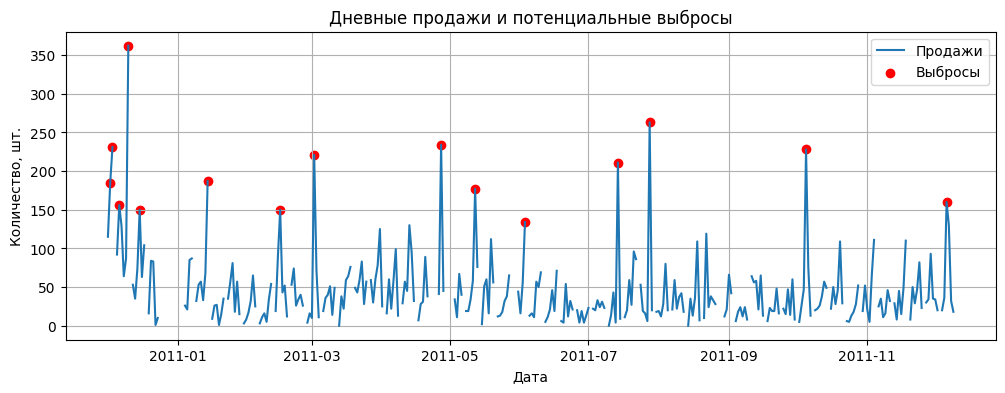

In [25]:
def flag_outliers(s):
    x = s.dropna()
    med = x.median()
    mad = median_abs_deviation(x, scale='normal')

    if mad > 0:
        return (abs(s - med) / mad > 3.5).fillna(False)

    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 3 * iqr) | (s > q3 + 3 * iqr)).fillna(False)


flags = flag_outliers(daily)
print('Потенциальных выбросов:', flags.sum())

plt.figure(figsize=(12, 4))
plt.plot(daily.index, daily.values, label='Продажи')
plt.scatter(daily.index[flags], daily[flags], color='red', label='Выбросы')
plt.title('Дневные продажи и потенциальные выбросы')
plt.xlabel('Дата')
plt.ylabel('Количество, шт.')
plt.legend()
plt.show()

Найдено 15 потенциальных выбросов. Оставляем их без изменений, поскольку нет оснований считать эти продажи ошибками.

## Шаг 3. Описательный анализ

### 3.1. Статистики

Посчитаем основные характеристики дневного, недельного и месячного рядов: среднее, медиану, разброс, квартили и долю нулей. Пропуски не заменяем нулём.

In [26]:
def describe_series(s):
    x = s.dropna()
    return pd.Series({
        'Наблюдений': len(x),
        'Пропусков': s.isna().sum(),
        'Среднее': x.mean(),
        'Медиана': x.median(),
        'Дисперсия': x.var(),
        'Стандартное отклонение': x.std(),
        'CV': x.std() / x.mean() if x.mean() else np.nan,
        'Минимум': x.min(),
        'Максимум': x.max(),
        'Размах': x.max() - x.min(),
        'Q1': x.quantile(0.25),
        'Q3': x.quantile(0.75),
        'IQR': x.quantile(0.75) - x.quantile(0.25),
        'Доля нулей': (x == 0).mean()
    })


stats = pd.DataFrame({
    'Дни': describe_series(daily),
    'Недели': describe_series(weekly),
    'Месяцы': describe_series(monthly)
})
display(stats.round(3))

,Дни,Недели,Месяцы
Наблюдений,305.000,53.000,13.000
Пропусков,69.000,1.000,0.000
Среднее,45.505,261.868,1067.615
Медиана,32.000,235.000,1054.000
Дисперсия,2215.014,17294.886,154239.756
Стандартное отклонение,47.064,131.510,392.734
CV,1.034,0.502,0.368
Минимум,0.000,85.000,450.000
Максимум,362.000,851.000,2093.000
Размах,362.000,766.000,1643.000


Продажи заметно колеблются. Дневные, недельные и месячные суммы нельзя напрямую сравнивать между собой из-за разной длины интервалов.

### 3.2. Среднее и разброс во времени

Построим скользящие среднее и стандартное отклонение за 28 дней. Также сравним первую и вторую половины периода.

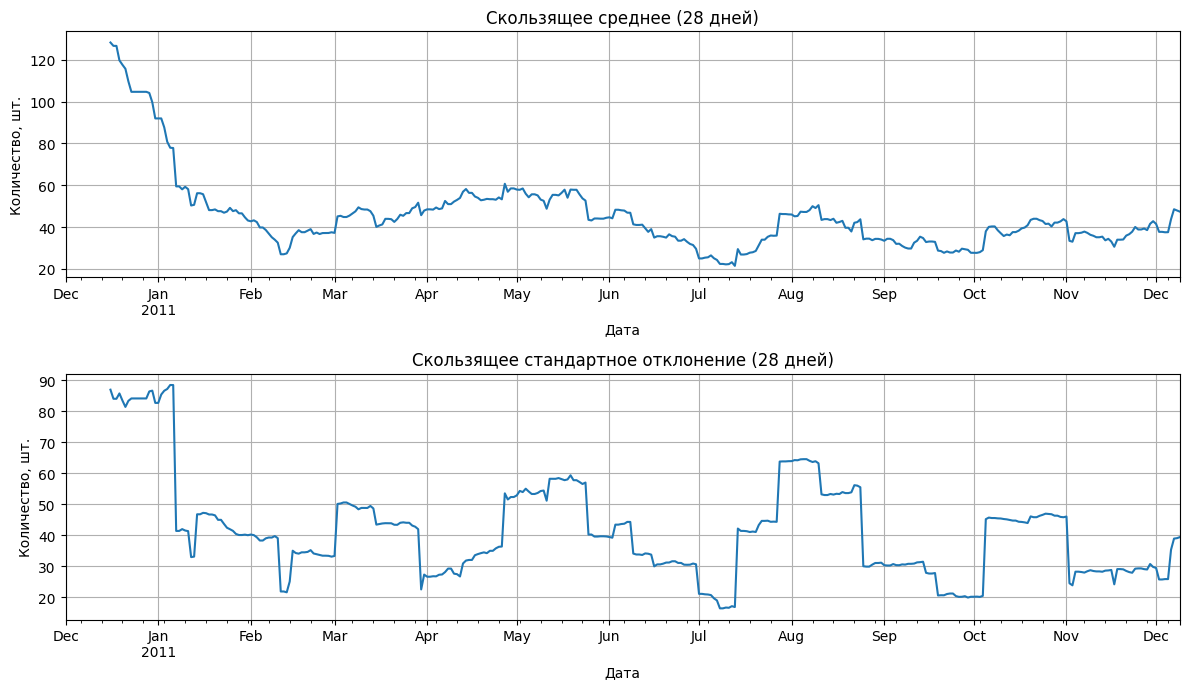

,Среднее,Медиана,Std
Первая половина,54.89,40.0,53.19
Вторая половина,37.00,24.0,38.98


In [27]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
daily.rolling(28, min_periods=14).mean().plot(ax=axes[0])
daily.rolling(28, min_periods=14).std().plot(ax=axes[1])
axes[0].set_title('Скользящее среднее (28 дней)')
axes[1].set_title('Скользящее стандартное отклонение (28 дней)')
for ax in axes:
    ax.set_xlabel('Дата')
    ax.set_ylabel('Количество, шт.')
plt.tight_layout()
plt.show()

middle = daily.index.min() + (daily.index.max() - daily.index.min()) / 2
halves = {
    'Первая половина': daily.loc[:middle].dropna(),
    'Вторая половина': daily.loc[middle:].dropna()
}
comparison = pd.DataFrame({
    name: {'Среднее': s.mean(), 'Медиана': s.median(), 'Std': s.std()}
    for name, s in halves.items()
}).T
display(comparison.round(2))

Средние дневные продажи снизились с 54,89 до 37,00 единиц, стандартное отклонение  с 53,19 до 38,98. Во второй половине периода и уровень, и разброс продаж ниже.

## Шаг 4. Декомпозиция

Разложим дневной ряд с помощью STL на тренд, сезонную компоненту и остатки. Проверим период 7 дней. Для STL временно интерполируем пропуски, но исходный ряд не изменяем.

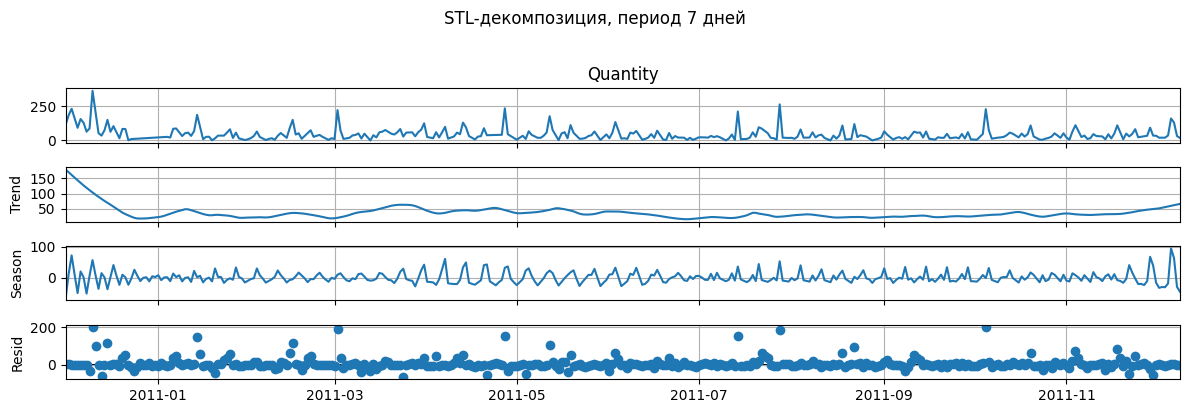

Сила сезонности: 0.314
По наблюдаемым дням: 0.311
Среднее остатка: 6.75
Стандартное отклонение остатка: 32.42


In [28]:
def decompose_daily(s, period=7):
    filled = s.interpolate(method='time', limit_direction='both')
    result = STL(filled, period=period, robust=True).fit()
    return result, filled


stl, daily_for_stl = decompose_daily(daily)
stl.plot()
plt.suptitle('STL-декомпозиция, период 7 дней', y=1.02)
plt.tight_layout()
plt.show()

v = np.var(stl.seasonal + stl.resid)
strength = max(0, 1 - np.var(stl.resid) / v)

observed = daily.notna()
v_obs = np.var(stl.seasonal[observed] + stl.resid[observed])
strength_observed = max(0, 1 - np.var(stl.resid[observed]) / v_obs)

print('Сила сезонности:', round(strength, 3))
print('По наблюдаемым дням:', round(strength_observed, 3))
print('Среднее остатка:', round(stl.resid.mean(), 2))
print('Стандартное отклонение остатка:', round(stl.resid.std(), 2))

Сила семидневной сезонности 0,314 (по датам с наблюдениями 0,311). Выраженная недельная сезонность не подтверждается. Тренд меняется плавно, в остатках есть всплески. Результат зависит от интерполяции.

## Шаг 5. Стационарность

### 5.1. ADF и KPSS

Проверим самый длинный непрерывный участок полных недель: дневной ряд содержит пропуски, а месячный слишком короткий. Для ADF нулевая гипотеза : наличие единичного корня, для KPSS — стационарность относительно уровня. Используем уровень значимости 0,05. Для сравнения проверим первую разность.

Период: 2011-01-09 — 2011-12-04


/tmp/ipykernel_50/3573127827.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(s, autolag='AIC')[1]
/tmp/ipykernel_50/3573127827.py:9: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_p = kpss(s, regression='c', nlags='auto')[1]
/tmp/ipykernel_50/3573127827.py:9: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. 

,Недельный ряд,Первая разность
N,48,47
ADF p,0.0,0.0
KPSS p,0.1,0.1
вывод,согласуется со стационарностью,согласуется со стационарностью


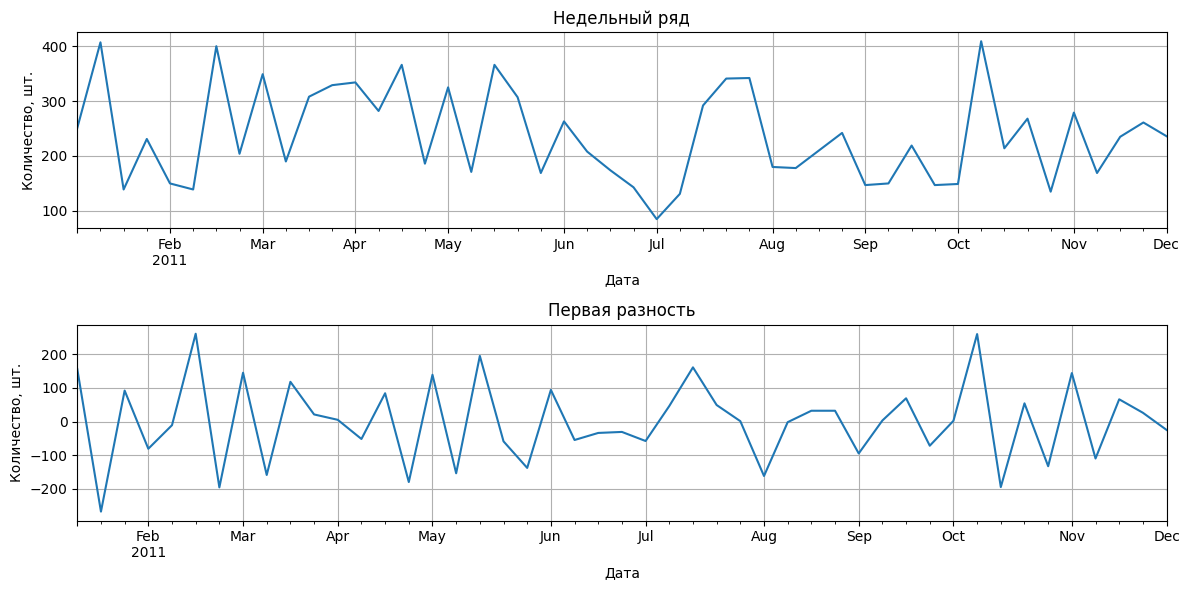

In [29]:
def longest_contiguous_segment(s):
    groups = s.notna().ne(s.notna().shift()).cumsum()
    parts = [x for _, x in s.dropna().groupby(groups[s.notna()])]
    return max(parts, key=len)


def stationarity_tests(s):
    adf_p = adfuller(s, autolag='AIC')[1]
    kpss_p = kpss(s, regression='c', nlags='auto')[1]

    if adf_p < 0.05 and kpss_p >= 0.05:
        conclusion = 'согласуется со стационарностью'
    elif adf_p >= 0.05 and kpss_p < 0.05:
        conclusion = 'согласуется с нестационарностью'
    else:
        conclusion = 'результат неоднозначен'

    return pd.Series({'N': len(s), 'ADF p': adf_p, 'KPSS p': kpss_p, 'вывод': conclusion})


base = longest_contiguous_segment(full_weeks)
first_diff = base.diff().dropna()
results = pd.DataFrame({
    'Недельный ряд': stationarity_tests(base),
    'Первая разность': stationarity_tests(first_diff)
})

print('Период:', base.index.min().date(), '—', base.index.max().date())
display(results)

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
base.plot(ax=axes[0], title='Недельный ряд')
first_diff.plot(ax=axes[1], title='Первая разность')
for ax in axes:
    ax.set_xlabel('Дата')
    ax.set_ylabel('Количество, шт.')
plt.tight_layout()
plt.show()

На 48 последовательных неделях тест ADF даёт $p \approx 3{,}67 \cdot 10^{-9}$, а тест KPSS — $p \geq 0{,}1$. При уровне значимости $\alpha = 0{,}05$ результаты согласуются со стационарностью выбранного участка, поэтому дифференцирование не требуется. На весь исходный дневной ряд этот вывод не распространяется.

### 5.2. ACF и PACF

Посмотрим автокорреляции недельного ряда и первой разности, чтобы сравнить зависимости между соседними наблюдениями.

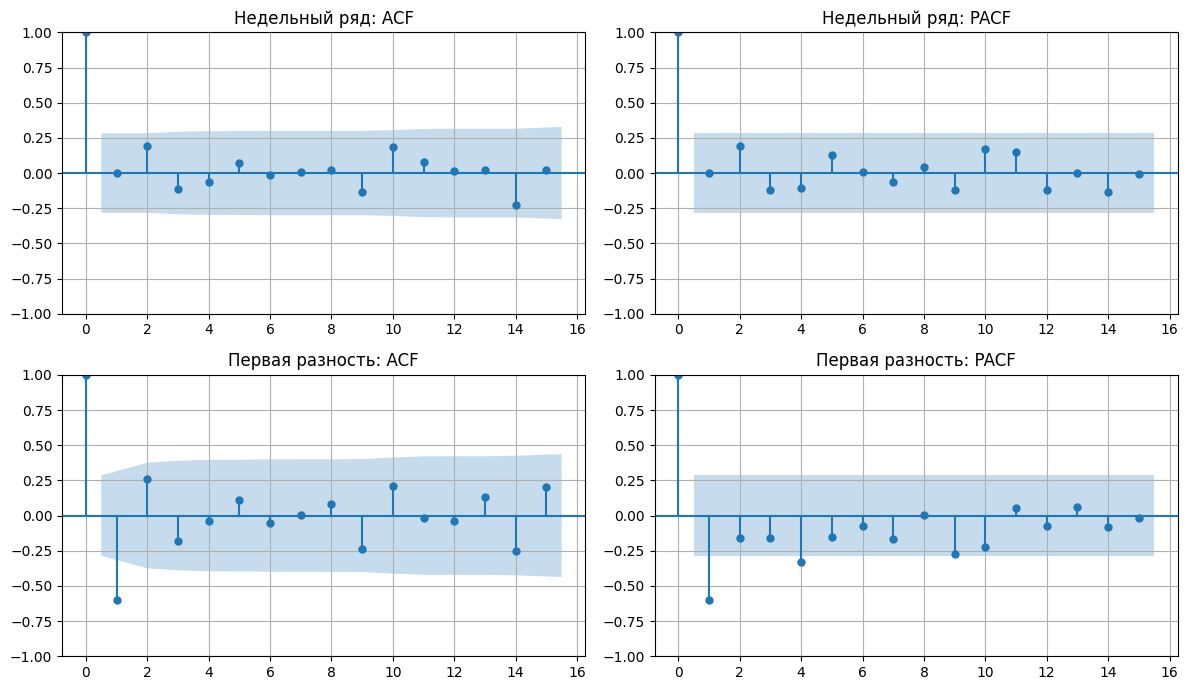

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

plot_acf(base, lags=15, ax=axes[0, 0], title='Недельный ряд: ACF')
plot_pacf(base, lags=15, ax=axes[0, 1], method='ywm', title='Недельный ряд: PACF')
plot_acf(first_diff, lags=15, ax=axes[1, 0], title='Первая разность: ACF')
plot_pacf(first_diff, lags=15, ax=axes[1, 1], method='ywm', title='Первая разность: PACF')

plt.tight_layout()
plt.show()

После дифференцирования корреляции меняются. По ACF/PACF нельзя самостоятельно сделать вывод о стационарности или сезонности.

## Шаг 6. Функции

Основные операции оформлены в функции. Повторим расчёты, чтобы проверить совпадение результатов.

In [31]:
daily2, weekly2, monthly2 = build_series(item, sales)

pd.testing.assert_series_equal(daily, daily2)
pd.testing.assert_series_equal(weekly, weekly2)
pd.testing.assert_series_equal(monthly, monthly2)

print('Повторная агрегация совпадает с исходной.')
print('Выбросов при повторной проверке:', flag_outliers(daily2).sum())
print('Недель в непрерывном участке:', len(longest_contiguous_segment(full_weeks)))

Повторная агрегация совпадает с исходной.
Выбросов при повторной проверке: 15
Недель в непрерывном участке: 48


Повторные расчёты совпали. Для воспроизведения работы достаточно подключить Online Retail и выполнить все ячейки по порядку.

## Итог

Для товара `22423` построены ряды продаж по дням, неделям и месяцам. Обнаружены 69 дат без наблюдений и 15 потенциальных выбросов, исходные значения не изменялись. Вторая половина периода характеризуется более низким уровнем продаж. Убедительной семидневной сезонности не выявлено. ADF и KPSS согласуются со стационарностью выбранных 48 недель.

Ограничения: неизвестен график работы магазина, для STL использовалась интерполяция, крайние периоды неполные.